<a href="https://colab.research.google.com/github/europecodingschool/ECS---VB---YZ---08.26/blob/main/VB_YZ_Ders_21_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import tensorflow as tf
import keras #tf.keras kullanım vardı. eski kaynaklarda aynı şeydir.

In [6]:
print("Tensorflow sürümü:", tf.__version__)
print("Keras sürümü:", keras.__version__)

Tensorflow sürümü: 2.21.0
Keras sürümü: 3.13.2


In [8]:
skaler = tf.constant(7)
vektor = tf.constant([12,2,1])
matris = tf.constant([[1,2],[3,4]])

In [10]:
print(skaler)
print(vektor)
print(matris)

tf.Tensor(7, shape=(), dtype=int32)
tf.Tensor([12  2  1], shape=(3,), dtype=int32)
tf.Tensor(
[[1 2]
 [3 4]], shape=(2, 2), dtype=int32)


In [26]:
#UYGULAMA İLK SİNİR AĞI
#Kütüphaneleri getir
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from keras import layers

In [14]:
#VERİYİ YÜKLEME
df = pd.read_csv("/content/e_ticaret_oturumlari.csv")
df.head()

,sayfa_sayisi,oturum_suresi_dk,sepete_ekleme,onceki_alisveris,indirim_kuponu,cihaz,trafik_kaynagi,hafta_sonu,satin_aldi
0,11,11.0,2,2,1,Masaüstü,Sosyal Medya,0,1
1,9,7.9,1,0,0,Mobil,Reklam,0,0
2,15,21.8,1,2,1,Masaüstü,Organik,0,0
3,12,10.7,1,1,1,Masaüstü,Sosyal Medya,0,1
4,6,6.7,1,0,0,Mobil,Organik,0,0


In [16]:
df.shape

(3000, 9)

In [18]:
df.describe()

,sayfa_sayisi,oturum_suresi_dk,sepete_ekleme,onceki_alisveris,indirim_kuponu,hafta_sonu,satin_aldi
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,11.005667,14.135767,1.020000,1.324333,0.213000,0.299000,0.466667
std,3.478458,5.717443,1.048475,1.154810,0.409496,0.457896,0.498971
min,2.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,9.000000,10.100000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,11.000000,13.400000,1.000000,1.000000,0.000000,0.000000,0.000000
75%,13.000000,17.500000,2.000000,2.000000,0.000000,1.000000,1.000000
max,25.000000,41.700000,8.000000,7.000000,1.000000,1.000000,1.000000


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sayfa_sayisi      3000 non-null   int64  
 1   oturum_suresi_dk  3000 non-null   float64
 2   sepete_ekleme     3000 non-null   int64  
 3   onceki_alisveris  3000 non-null   int64  
 4   indirim_kuponu    3000 non-null   int64  
 5   cihaz             3000 non-null   object 
 6   trafik_kaynagi    3000 non-null   object 
 7   hafta_sonu        3000 non-null   int64  
 8   satin_aldi        3000 non-null   int64  
dtypes: float64(1), int64(6), object(2)
memory usage: 211.1+ KB


In [22]:
df.isnull().sum()

,0
sayfa_sayisi,0
oturum_suresi_dk,0
sepete_ekleme,0
onceki_alisveris,0
indirim_kuponu,0
cihaz,0
trafik_kaynagi,0
hafta_sonu,0
satin_aldi,0


In [24]:
df['satin_aldi'].value_counts()

,count
satin_aldi,
0,1600
1,1400


<Axes: xlabel='satin_aldi', ylabel='count'>

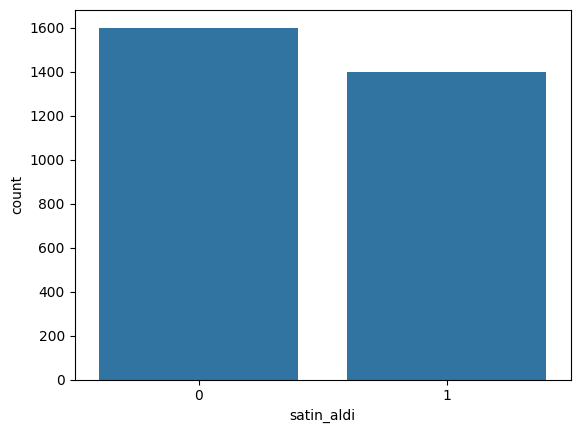

In [28]:
from re import X
sns.countplot(data=df, x='satin_aldi')
#
#

In [33]:
# X ve y olarak ayırma - VERİ TİPİ SAYISAL OLMAYANLARI DÖNÜŞTÜRME

X = df.drop(columns=['satin_aldi'])
y = df['satin_aldi']

X = pd.get_dummies(X, columns=["cihaz","trafik_kaynagi"], dtype=int)
print("Özellik Sayısı:",X.shape[1])
print(X.columns.tolist())

Özellik Sayısı: 13
['sayfa_sayisi', 'oturum_suresi_dk', 'sepete_ekleme', 'onceki_alisveris', 'indirim_kuponu', 'hafta_sonu', 'cihaz_Masaüstü', 'cihaz_Mobil', 'cihaz_Tablet', 'trafik_kaynagi_E-posta', 'trafik_kaynagi_Organik', 'trafik_kaynagi_Reklam', 'trafik_kaynagi_Sosyal Medya']


In [35]:
#Train ve Test Olarak Ayırma

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Eğitim:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Eğitim: (2400, 13) (2400,)
Test: (600, 13) (600,)


In [37]:
#Ölçeklendirme
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [39]:
#Modeli Kurma - İlk Sinir Ağını Kurma
keras.utils.set_random_seed(42) # Modelimizin benzer sonuçlar vermesi için.

model = keras.Sequential([
    keras.Input(shape=(13,)), # Modele her seferinde 13 özelliklik bir ziyaretçi geleceğini söylüyoruz.
    layers.Dense(16, activation='relu'), # 16 nöronlu, tam bağlantılı gizli ilk katman
    layers.Dense(8, activation='relu'), # 8 nöronlu ikinci gizli katman
    layers.Dense(1, activation='sigmoid') # ikili sınıflandırma yaptığımız için çıktı katmanı.
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 369 (1.44 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
# MODELİ DERLEME - Modelin nasıl öğreneceğini söyler.

model.compile(optimizer="adam", #modelin varsayılan öğrenme oranı)learning_rate
              loss="binary_crossentropy",# ikili sınıflandırma için kayıp fonksiyonu. Hedefimiz bunu küçültmek
              metrics=["accuracy"]) # Eğitim sırasındaki doğruluğu hesaplar.


In [44]:
# MODELİ EĞİTME (fit)

gecmis = model.fit(X_train_s, y_train, epochs=50, # Eğitim verisi modelden kaç kez geçecek.
                   batch_size=32, # Ağırlıklar her batch size değerinde bir güncelenecek. Yani 322 ziyaretçide 1 güncellenecek.
                   validation_split=0.2,) # Eğitim verisinin son %20 si eğitimde kullanılmayıp her epoch sonrası modeli kontrol için kullanılacak.

Epoch 1/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4734 - loss: 0.7418 - val_accuracy: 0.4792 - val_loss: 0.7226
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5667 - loss: 0.6653 - val_accuracy: 0.5875 - val_loss: 0.6700
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6641 - loss: 0.6185 - val_accuracy: 0.6833 - val_loss: 0.6265
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7240 - loss: 0.5748 - val_accuracy: 0.7250 - val_loss: 0.5819
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7458 - loss: 0.5352 - val_accuracy: 0.7625 - val_loss: 0.5423
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7750 - loss: 0.5015 - val_accuracy: 0.7625 - val_loss: 0.5114
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7865 - loss: 0.4759 - val_accuracy: 0.7563 - val_loss: 0.4904
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7969 - loss: 0.4588 - val_accuracy: 0.7646 - val_loss

# loss ve val_loss birlikte düşüyorsa sağlıklı öğrenme vardır
# loss ve val_loss birlikte yüksek kalıyorsa düşmüyorsa az öğrenme vardır.
loss düşmeye devam ediyor ve val_loss durduysa aşırı öğrenme vardır.

In [45]:
# TEST VERİSİNİ DEĞERLENDİRMEYE

test_kayip, test_dogruluk = model.evaluate(X_test_s, y_test)
print("Test Kaybı: {:.2f}".format(test_kayip))
print("Test Doğruluğu: {:.2f}".format(test_dogruluk))

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7817 - loss: 0.4500  
Test Kaybı: 0.45
Test Doğruluğu: 0.78
